# 상2 트랙 분석 — 이름

- 이 노트북의 파일 이름을 수행한 트랙에 맞게 바꿉니다: `하트랙_분석.ipynb` · `중트랙_분석.ipynb` · `상트랙_분석.ipynb`
- 데이터: 가상의 가전 조립공장, 2026년 10월 (합성 데이터)
- SQL 파일은 `../sql/`, 차트는 `../images/`에 저장합니다
- 미션마다 **지시 해석 → 설계 → SQL → 검산 → 차트 → 보고 문장** 순서로 채웁니다

## 0. 준비

아래 두 셀은 그대로 실행합니다. 실행하기 전에 프로젝트 폴더에 `.env` 파일이 있어야 합니다(`.env.example`을 복사해 비밀번호 입력).

In [7]:
# ===== 강사 제공 코드: 그대로 복사해서 사용합니다 =====
import os
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

load_dotenv()
engine = create_engine(URL.create(
    "postgresql+psycopg2",
    username=os.getenv("PG_USER", "postgres"), password=os.getenv("PG_PASSWORD") or None,
    host=os.getenv("PG_HOST", "localhost"), port=int(os.getenv("PG_PORT", "5432")),
    database=os.getenv("PG_DB", "postgres"),
))

def q(sql, **params):        # SELECT 문을 실행하고 결과를 DataFrame으로 돌려줍니다
    with engine.connect() as conn:
        return pd.read_sql(text(sql), conn, params=params)

def q_file(name):            # ../sql 폴더의 SQL 파일을 읽어 실행합니다
    return q(Path("../sql", name).read_text(encoding="utf-8"))
# ===== 강사 제공 코드 끝 =====

In [8]:
# 한글 글꼴 (Windows: Malgun Gothic / macOS: AppleGothic)
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

q("SELECT line_code, line_name, plan_per_shift FROM line_master")

,line_code,line_name,plan_per_shift
0,L1,냉장고 조립라인,400
1,L2,세탁기 조립라인,450
2,L3,에어컨 조립라인,350


위 셀에서 라인 3개가 표로 나오면 연결이 된 것입니다. **여기부터는 직접 작성합니다.**

## 미션 1. 상2

> "설비고장 나기 전에 온도나 진동에 이상 신호가 있었는지 확인해봐." 

**1. 지시 해석** — 무엇을 보고해야 하는지 한 줄로: 설비 고장 전 시기, 온도, 진동 등의 로그 데이터 시각화
고장남 - 고장 전, 온도, 진동 로그 추출, 고장 시기 


**2. 설계** — 필요한 테이블 · 컬럼 · 계산식: 
- 테이블: 온도- sensor_hourly-temp_c / 진동- sensor_hourly-vibration_mm_s / 설비 정보-equipment_master / 시기-sensor_hourly-measured_at / 고장 설비 및 시기-production_result
- 계산식: 불량률(defect_qty/prod_qty), 고장 시점을 기준으로 기간을 나눔()

In [10]:
# 3~4. SQL 파일을 ../sql 폴더에 저장한 뒤 불러옵니다
# 예) df = q_file("하1_라인별_생산수량.sql")
df  = q_file("/Users/sojeongshin/Documents/GitHub/생산 DB X Python 미니 프로젝트/14. 생산DB_Python연동.sql")

In [26]:
# 5. 검산: 합계·건수를 다른 방법으로 한 번 더 확인합니다
q("SELECT COUNT(*)" \
    "FROM production_result" )



,count
0,162


In [18]:
q("SELECT COUNT(*)" \
    "FROM equipment_master" )

,count
0,9


In [19]:
q("SELECT COUNT(*)" \
    "FROM sensor_hourly" )

,count
0,5832


In [75]:
insert_sql = text("""
INSERT INTO quality_judgment (work_date, line_code, defect_rate, judgment)
VALUES (:work_date, :line_code, :defect_rate, :judgment)
""")

with engine.begin() as conn:   # 블록이 끝나면 COMMIT, 중간에 오류가 나면 ROLLBACK
    conn.execute(insert_sql, {"work_date": "2026-10-01", "line_code": "L1",
                              "defect_rate": 1.53, "judgment": "정상"})

q("SELECT work_date, line_code, defect_rate, judgment FROM quality_judgment")

,work_date,line_code,defect_rate,judgment
0,2026-10-01,L1,1.53,정상


In [ ]:
# 불량률 구하기 -> 불량개수 / 생산 개수

q("select result_id, prod_qty, defect_qty, work_date, "
  " round(defect_qty::numeric / nullif(prod_qty, 0), 4) as 불량률 " \
  " from production_result ")


,result_id,prod_qty,defect_qty,work_date,불량률
0,1,364,5,2026-10-01,0.0137
1,2,417,4,2026-10-01,0.0096
2,3,320,2,2026-10-01,0.0063
3,4,353,6,2026-10-01,0.0170
4,5,441,7,2026-10-01,0.0159
...,...,...,...,...,...
157,158,410,6,2026-10-31,0.0146
158,159,307,3,2026-10-31,0.0098
159,160,380,5,2026-10-31,0.0132
160,161,449,11,2026-10-31,0.0245


In [54]:
# 0.015 불량률 임계치 넘는 결과 값 출력

q("select result_id, prod_qty, defect_qty, work_date, "
  " round(defect_qty::numeric / nullif(prod_qty, 0), 4) as 불량률 " \
  " from production_result " \
  " where round(defect_qty::numeric / nullif(prod_qty, 0), 4) > 0.015" \
  " order by 불량률")

,result_id,prod_qty,defect_qty,work_date,불량률
0,72,331,5,2026-10-14,0.0151
1,84,332,5,2026-10-16,0.0151
2,113,394,6,2026-10-22,0.0152
3,27,330,5,2026-10-06,0.0152
4,131,391,6,2026-10-26,0.0153
...,...,...,...,...,...
71,74,442,12,2026-10-15,0.0271
72,71,424,15,2026-10-14,0.0354
73,77,440,20,2026-10-15,0.0455
74,80,419,21,2026-10-16,0.0501


In [57]:
# 불량률 임계치 구하기 : 평균 + k × 표준편차

defect_avg, defect_std = q("select avg(불량률), stddev(불량률) " \
    "from (" \
    "select result_id, "
    " round(defect_qty::numeric / nullif(prod_qty, 0), 4) as 불량률 " \
    " from production_result ) t"
    ).iloc[0].astype(float)

In [63]:
# k=2 임계치 구하기
tol2 = round(defect_avg + 2 * defect_std, 4)

# k=3 임계치 구하기
tol3 = round(defect_avg + 3 * defect_std, 4)

print(tol2, tol3)

0.0296 0.0367


In [65]:
# tol2 기준으로 불량 설비 추출
q("select result_id, prod_qty, defect_qty, work_date, "
  " round(defect_qty::numeric / nullif(prod_qty, 0), 4) as 불량률 " \
  " from production_result " \
  " where round(defect_qty::numeric / nullif(prod_qty, 0), 4) > :tol", tol= tol2 \
  )

,result_id,prod_qty,defect_qty,work_date,불량률
0,71,424,15,2026-10-14,0.0354
1,77,440,20,2026-10-15,0.0455
2,80,419,21,2026-10-16,0.0501
3,83,411,24,2026-10-16,0.0584


In [74]:
q("select round(avg(temp_c), 2) as l_temp_c, round(avg(vibration_mm_s), 2) as l_vib " \
"from sensor_hourly s " \
    "join equipment_master e " \
    "on s.equip_code = e.equip_code " \
"group by line_code")

,l_temp_c,l_vib
0,36.07,2.03
1,32.69,2.00
2,36.69,1.99


In [ ]:
# 1) 일자, 라인별 불량률 집계
daily = q("""
    select work_date, line_code,
           round(sum(defect_qty) * 100.0 / nullif(sum(prod_qty), 0), 2) as defect_rate
    from production_result
    group by work_date, line_code
""")
daily['defect_rate'] = daily['defect_rate'].astype(float)

# 2) 임계치 계산 (평균 + 2k는 주의, 평균 + 3k는 이상)
avg, std = daily['defect_rate'].mean(), daily['defect_rate'].std()
warn, alarm = avg + 2 * std, avg + 3 * std

def judge(rate):
    if rate > alarm: return '이상'
    if rate > warn:  return '주의'
    return '정상'

daily['judgment'] = daily['defect_rate'].apply(judge)

# 3) INSERT
with engine.begin() as conn:         
    conn.execute(text("""
        insert into quality_judgment (work_date, line_code, defect_rate, judgment)
        values (:work_date, :line_code, :defect_rate, :judgment)
        on conflict (work_date, line_code)
        do update set defect_rate = excluded.defect_rate,
                      judgment    = excluded.judgment,
                      judged_at   = now()
    """), daily.to_dict('records'))  

q("select judgment, count(*) from quality_judgment group by judgment")


,judgment,count
0,정상,78
1,주의,1
2,이상,2


In [ ]:
q("select equip_code, temp_c, vibration_mm_s" \
" from sensor_hourly" \
" where ")

In [ ]:
insert_sql = text("""
INSERT INTO quality_judgment (work_date, line_code, defect_rate, judgment)
VALUES (:work_date, :line_code, :defect_rate, :judgment)
""")

with engine.begin() as conn:   # 블록이 끝나면 COMMIT, 중간에 오류가 나면 ROLLBACK
    conn.execute(insert_sql, {"work_date": "2026-10-01", "line_code": "L1",
                              "defect_rate": 1.53, "judgment": "정상"})

q("SELECT work_date, line_code, defect_rate, judgment FROM quality_judgment")

In [84]:
import numpy as np

# 1) 판정 테이블 생성 (이미 있으면 건너뜀)
with engine.begin() as conn:
    conn.execute(text("""
        create table if not exists equip_judgment (
            judge_id    serial       primary key,
            work_date   date         not null,
            equip_code  varchar(10)  not null references equipment_master(equip_code),
            avg_vib     numeric(5,2) not null,
            judgment    varchar(10)  not null check (judgment in ('정상','주의','이상')),
            judged_by   varchar(30)  not null default 'python',
            judged_at   timestamp    not null default current_timestamp,
            unique (work_date, equip_code)
        )
    """))

# 2) 설비·일자별 평균 진동
daily = q("""
    select measured_at::date as work_date, equip_code,
           round(avg(vibration_mm_s), 2) as avg_vib
    from sensor_hourly
    where vibration_mm_s is not null
    group by 1, 2
""")
daily['avg_vib'] = daily['avg_vib'].astype(float)

# 3) 설비별 임계치 (평균 + 2k는 주의, 평균 + 3k는 이상)
g = daily.groupby('equip_code')['avg_vib']
daily['warn']  = g.transform('mean') + 2 * g.transform('std')
daily['alarm'] = g.transform('mean') + 3 * g.transform('std')

daily['judgment'] = np.select(
    [daily['avg_vib'] > daily['alarm'], daily['avg_vib'] > daily['warn']],
    ['이상', '주의'],
    default='정상'
)

# 4) 모든 행을 한 번에 INSERT (다시 실행하면 기존 행을 덮어씀)
cols = ['work_date', 'equip_code', 'avg_vib', 'judgment']
with engine.begin() as conn:
    conn.execute(text("""
        insert into equip_judgment (work_date, equip_code, avg_vib, judgment)
        values (:work_date, :equip_code, :avg_vib, :judgment)
        on conflict (work_date, equip_code)
        do update set avg_vib   = excluded.avg_vib,
                      judgment  = excluded.judgment,
                      judged_at = now()
    """), daily[cols].to_dict('records'))

# 5) 결과 확인: 설비별 판정 건수
q("""
    select e.line_code, j.equip_code, e.equip_name, j.judgment, count(*) as 일수
    from equip_judgment j
    join equipment_master e using (equip_code)
    group by 1, 2, 3, 4
    order by 1, 2, 4
""")


,line_code,equip_code,equip_name,judgment,일수
0,L1,EQ-101,우레탄 발포기,정상,27
1,L1,EQ-102,도어 조립로봇,정상,26
2,L1,EQ-102,도어 조립로봇,주의,1
3,L1,EQ-103,냉력 검사기,정상,26
4,L1,EQ-103,냉력 검사기,주의,1
5,L2,EQ-201,드럼 용접기,이상,1
6,L2,EQ-201,드럼 용접기,정상,25
7,L2,EQ-201,드럼 용접기,주의,1
8,L2,EQ-202,모터 조립로봇,정상,27
9,L2,EQ-203,탈수 검사기,정상,26


In [85]:
q("select * from quality_judgment")

,judge_id,work_date,line_code,defect_rate,judgment,judged_by,judged_at,equip_code
0,2,2026-10-13,L3,1.35,정상,python,2026-11-20 15:27:03.937570,None
1,3,2026-10-13,L1,1.42,정상,python,2026-11-20 15:27:03.937570,None
2,4,2026-10-28,L3,1.11,정상,python,2026-11-20 15:27:03.937570,None
3,5,2026-10-23,L1,1.43,정상,python,2026-11-20 15:27:03.937570,None
4,6,2026-10-21,L3,1.23,정상,python,2026-11-20 15:27:03.937570,None
...,...,...,...,...,...,...,...,...
76,78,2026-10-22,L3,1.29,정상,python,2026-11-20 15:27:03.937570,None
77,79,2026-10-26,L3,1.34,정상,python,2026-11-20 15:27:03.937570,None
78,80,2026-10-17,L2,1.52,정상,python,2026-11-20 15:27:03.937570,None
79,81,2026-10-15,L1,1.58,정상,python,2026-11-20 15:27:03.937570,None


In [ ]:
import numpy as np

# 1) 테이블 구조 준비: 열 추가 + 고유 제약을 (일자, 설비)로 변경
with engine.begin() as conn:
    conn.execute(text("""
        alter table quality_judgment
          add column if not exists equip_code   varchar(10) references equipment_master(equip_code),
          add column if not exists avg_vib      numeric(5,2),   -- 일 평균 진동
          add column if not exists max_vib      numeric(5,2),   -- 일 최대 진동
          add column if not exists avg_temp     numeric(5,1),   -- 일 평균 온도
          add column if not exists max_temp     numeric(5,1),   -- 일 최대 온도
          add column if not exists sample_cnt   integer,        -- 부가: 측정 시간 수
          add column if not exists vib_warn     numeric(5,2),   -- 부가: 진동 주의 기준
          add column if not exists vib_alarm    numeric(5,2),   -- 부가: 진동 이상 기준
          add column if not exists temp_warn    numeric(5,1),   -- 부가: 온도 주의 기준
          add column if not exists temp_alarm   numeric(5,1),   -- 부가: 온도 이상 기준
          add column if not exists judge_reason varchar(50)     -- 부가: 판정 사유
    """))
    conn.execute(text("alter table quality_judgment drop constraint if exists quality_judgment_work_date_line_code_key"))
    conn.execute(text("delete from quality_judgment where equip_code is null"))   # 기존 라인 단위 행 제거
    conn.execute(text("""
        do $$ begin
          alter table quality_judgment add constraint uq_qj_date_equip unique (work_date, equip_code);
        exception when duplicate_object or duplicate_table then null;
        end $$
    """))

# 2) 설비·일자별 집계 + 해당 라인의 당일 불량률
daily = q("""
    with s as (
        select measured_at::date as work_date, equip_code,
               round(avg(vibration_mm_s), 2) as avg_vib,
               max(vibration_mm_s)           as max_vib,
               round(avg(temp_c), 1)         as avg_temp,
               max(temp_c)                   as max_temp,
               count(*)                      as sample_cnt
        from sensor_hourly
        group by 1, 2
    ),
    rate as (
        select work_date, line_code,
               round(sum(defect_qty) * 100.0 / nullif(sum(prod_qty), 0), 2) as defect_rate
        from production_result
        group by 1, 2
    )
    select s.*, e.line_code, r.defect_rate
    from s
    join equipment_master e using (equip_code)
    join rate r on r.work_date = s.work_date and r.line_code = e.line_code
""")
num = ['avg_vib', 'max_vib', 'avg_temp', 'max_temp', 'defect_rate']
daily[num] = daily[num].astype(float)

# 3) 설비별 임계치 (일 최댓값의 평균 + 2σ/3σ)
기준 = daily.groupby('equip_code')[['max_vib', 'max_temp']].agg(['mean', 'std'])
기준.columns = ['vib_mean', 'vib_std', 'temp_mean', 'temp_std']
기준['vib_warn']   = (기준['vib_mean']  + 2 * 기준['vib_std']).round(2)
기준['vib_alarm']  = (기준['vib_mean']  + 3 * 기준['vib_std']).round(2)
기준['temp_warn']  = (기준['temp_mean'] + 2 * 기준['temp_std']).round(1)
기준['temp_alarm'] = (기준['temp_mean'] + 3 * 기준['temp_std']).round(1)
daily = daily.merge(기준[['vib_warn', 'vib_alarm', 'temp_warn', 'temp_alarm']].reset_index(), on='equip_code')

# 4) 판정 + 판정 사유
vib_a  = daily['max_vib']  > daily['vib_alarm']
vib_w  = daily['max_vib']  > daily['vib_warn']
temp_a = daily['max_temp'] > daily['temp_alarm']
temp_w = daily['max_temp'] > daily['temp_warn']

daily['judgment'] = np.select([vib_a | temp_a, vib_w | temp_w], ['이상', '주의'], default='정상')

def reason(i):
    r = []
    if vib_a[i]:    r.append('진동 이상')
    elif vib_w[i]:  r.append('진동 주의')
    if temp_a[i]:   r.append('온도 이상')
    elif temp_w[i]: r.append('온도 주의')
    return ', '.join(r) or None
daily['judge_reason'] = [reason(i) for i in daily.index]

# 5) INSERT (다시 실행하면 덮어쓰기)
cols = ['work_date', 'equip_code', 'line_code', 'defect_rate',
        'avg_vib', 'max_vib', 'avg_temp', 'max_temp', 'sample_cnt',
        'vib_warn', 'vib_alarm', 'temp_warn', 'temp_alarm', 'judgment', 'judge_reason']
rows = daily[cols].astype(object).where(daily[cols].notna(), None).to_dict('records')   # NaN → NULL

with engine.begin() as conn:
    conn.execute(text(f"""
        insert into quality_judgment ({', '.join(cols)})
        values ({', '.join(':' + c for c in cols)})
        on conflict (work_date, equip_code) do update set
          {', '.join(f'{c} = excluded.{c}' for c in cols if c not in ('work_date', 'equip_code'))},
          judged_at = now()
    """), rows)

# 6) 확인
display(q("select * from quality_judgment order by work_date, equip_code limit 10"))
q("select judgment, count(*) from quality_judgment group by judgment order by 1")


,judge_id,work_date,line_code,defect_rate,judgment,judged_by,judged_at,equip_code,avg_vib,max_vib,avg_temp,max_temp,sample_cnt,vib_warn,vib_alarm,temp_warn,temp_alarm,judge_reason
0,233,2026-10-01,L1,1.53,정상,python,2026-11-20 16:13:58.586859,EQ-101,2.00,2.42,38.2,40.3,24,2.73,2.84,41.0,41.3,None
1,113,2026-10-01,L1,1.53,정상,python,2026-11-20 16:13:58.586859,EQ-102,2.01,2.34,32.1,33.8,24,2.75,2.89,34.9,35.3,None
2,231,2026-10-01,L1,1.53,정상,python,2026-11-20 16:13:58.586859,EQ-103,1.98,2.55,28.0,30.2,24,2.70,2.81,31.0,31.4,None
3,157,2026-10-01,L2,1.28,정상,python,2026-11-20 16:13:58.586859,EQ-201,2.04,2.77,45.3,47.6,24,3.30,3.63,57.0,61.1,None
4,99,2026-10-01,L2,1.28,정상,python,2026-11-20 16:13:58.586859,EQ-202,1.98,2.30,33.0,35.5,24,2.67,2.78,36.1,36.5,None
5,100,2026-10-01,L2,1.28,정상,python,2026-11-20 16:13:58.586859,EQ-203,1.96,2.39,28.9,31.4,24,2.78,2.91,32.0,32.4,None
6,156,2026-10-01,L3,0.92,정상,python,2026-11-20 16:13:58.586859,EQ-301,1.96,2.38,52.1,54.6,24,2.76,2.91,55.1,55.5,None
7,196,2026-10-01,L3,0.92,정상,python,2026-11-20 16:13:58.586859,EQ-302,2.02,2.48,30.0,32.2,24,2.82,2.99,33.0,33.3,None
8,308,2026-10-01,L3,0.92,정상,python,2026-11-20 16:13:58.586859,EQ-303,1.97,2.53,28.3,30.6,24,2.70,2.80,30.7,31.0,None
9,227,2026-10-02,L1,1.41,정상,python,2026-11-20 16:13:58.586859,EQ-101,1.96,2.53,38.1,40.2,24,2.73,2.84,41.0,41.3,None


,judgment,count
0,이상,1
1,정상,228
2,주의,14


In [89]:
with engine.begin() as conn:
    conn.execute(text("""
        with lr as (                                  -- 일자·라인당 1행 (설비 수만큼 중복되지 않게)
            select distinct work_date, line_code, defect_rate
            from quality_judgment
            where equip_code is not null
        ),
        th as (                                       -- 라인별 임계치: 평균 + k·σ
            select line_code, avg(defect_rate) + :k * stddev(defect_rate) as limit_rate
            from lr
            group by line_code
        )
        update quality_judgment qj
        set judgment     = case when qj.defect_rate > th.limit_rate then '이상' else '정상' end,
            judge_reason = case when qj.defect_rate > th.limit_rate
                                then '불량률 ' || qj.defect_rate || '% > 기준 ' || round(th.limit_rate, 2) || '%' end,
            judged_at    = now()
        from th
        where qj.line_code = th.line_code
          and qj.equip_code is not null
    """), {'k': 2})

q("select line_code, judgment, count(distinct work_date) as 일수 from quality_judgment group by 1, 2 order by 1, 2")


,line_code,judgment,일수
0,L1,이상,1
1,L1,정상,26
2,L2,이상,1
3,L2,정상,26
4,L3,정상,27


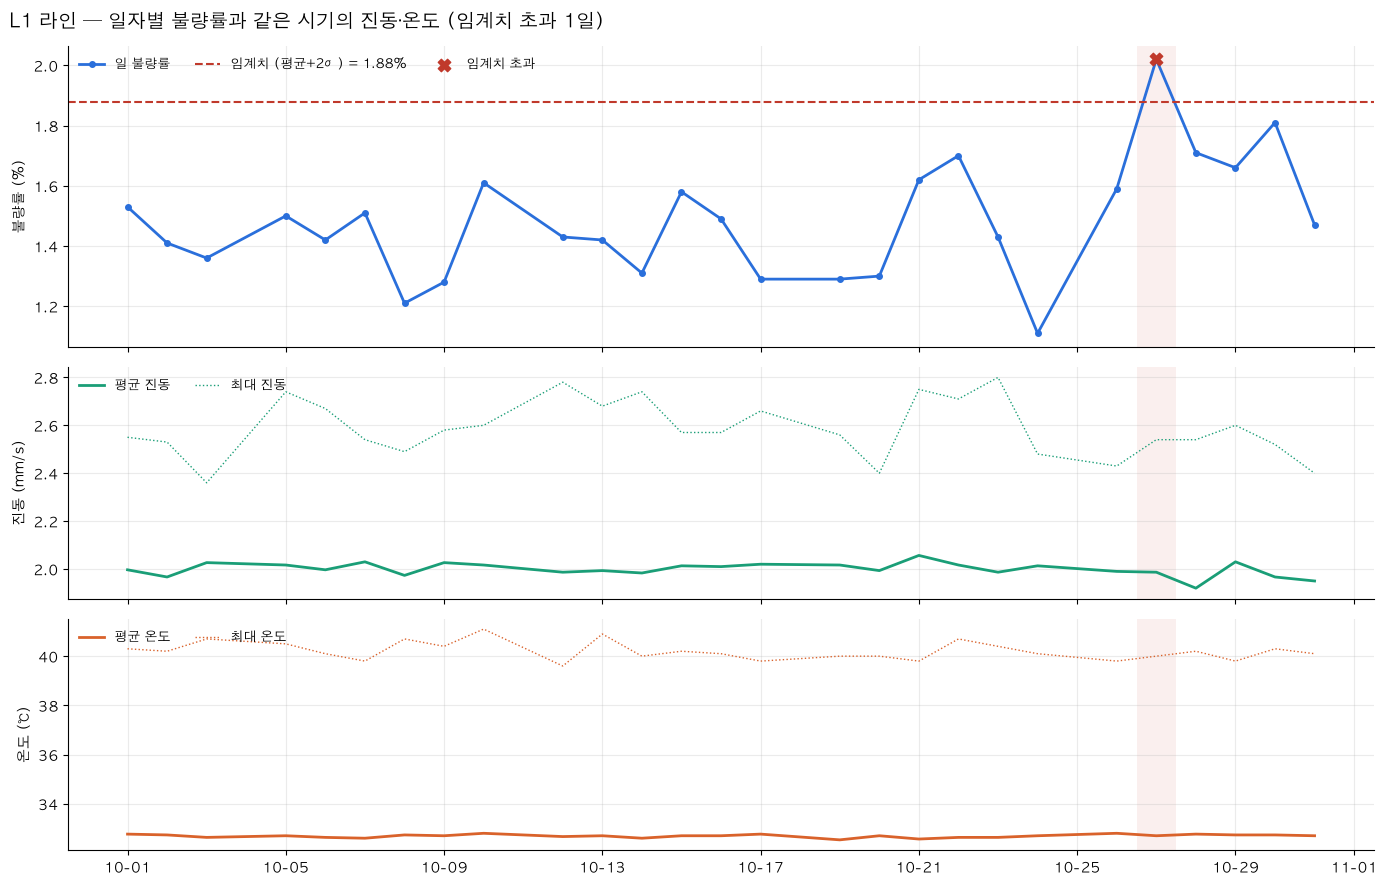

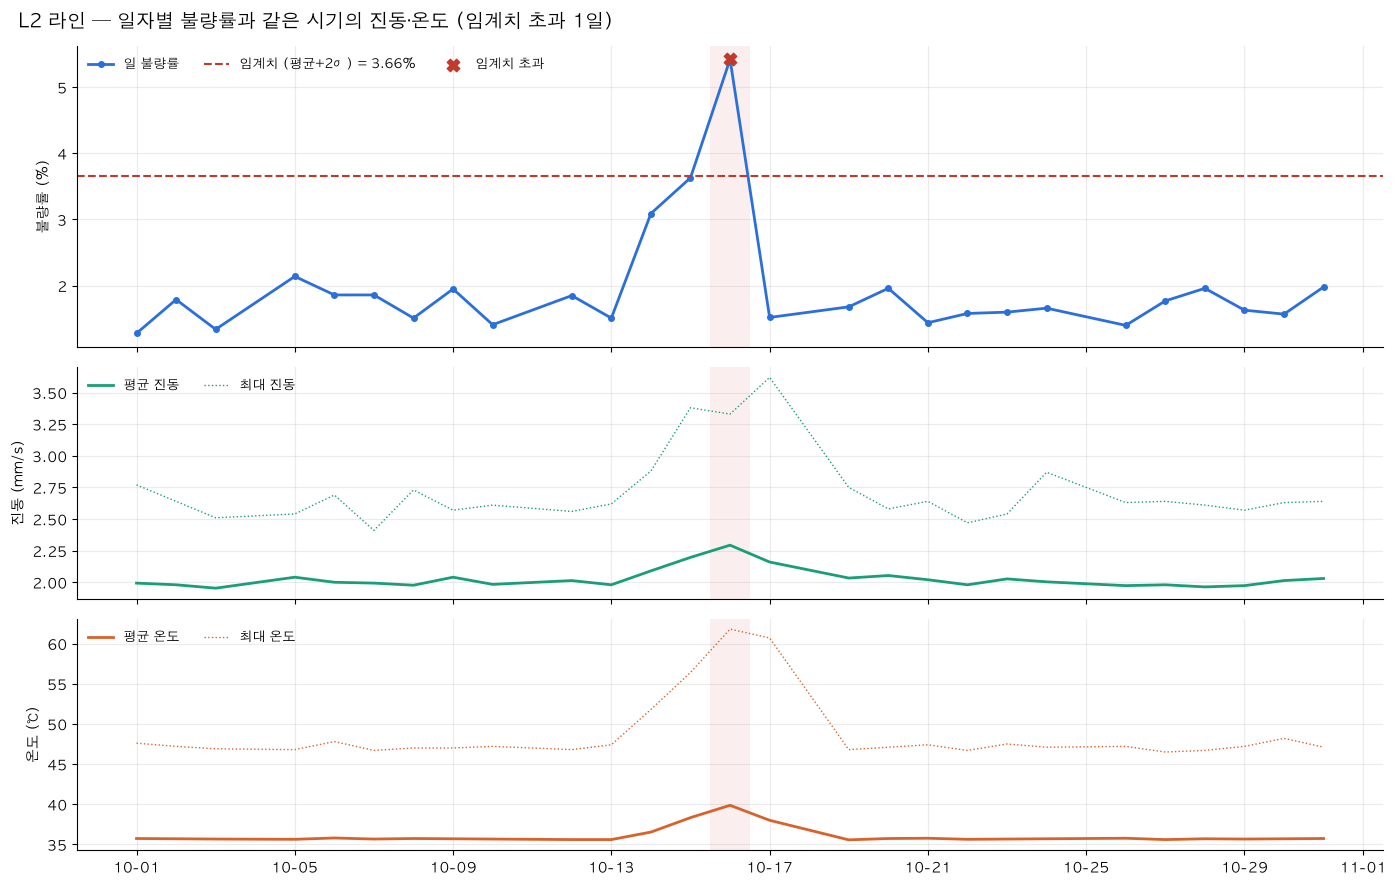

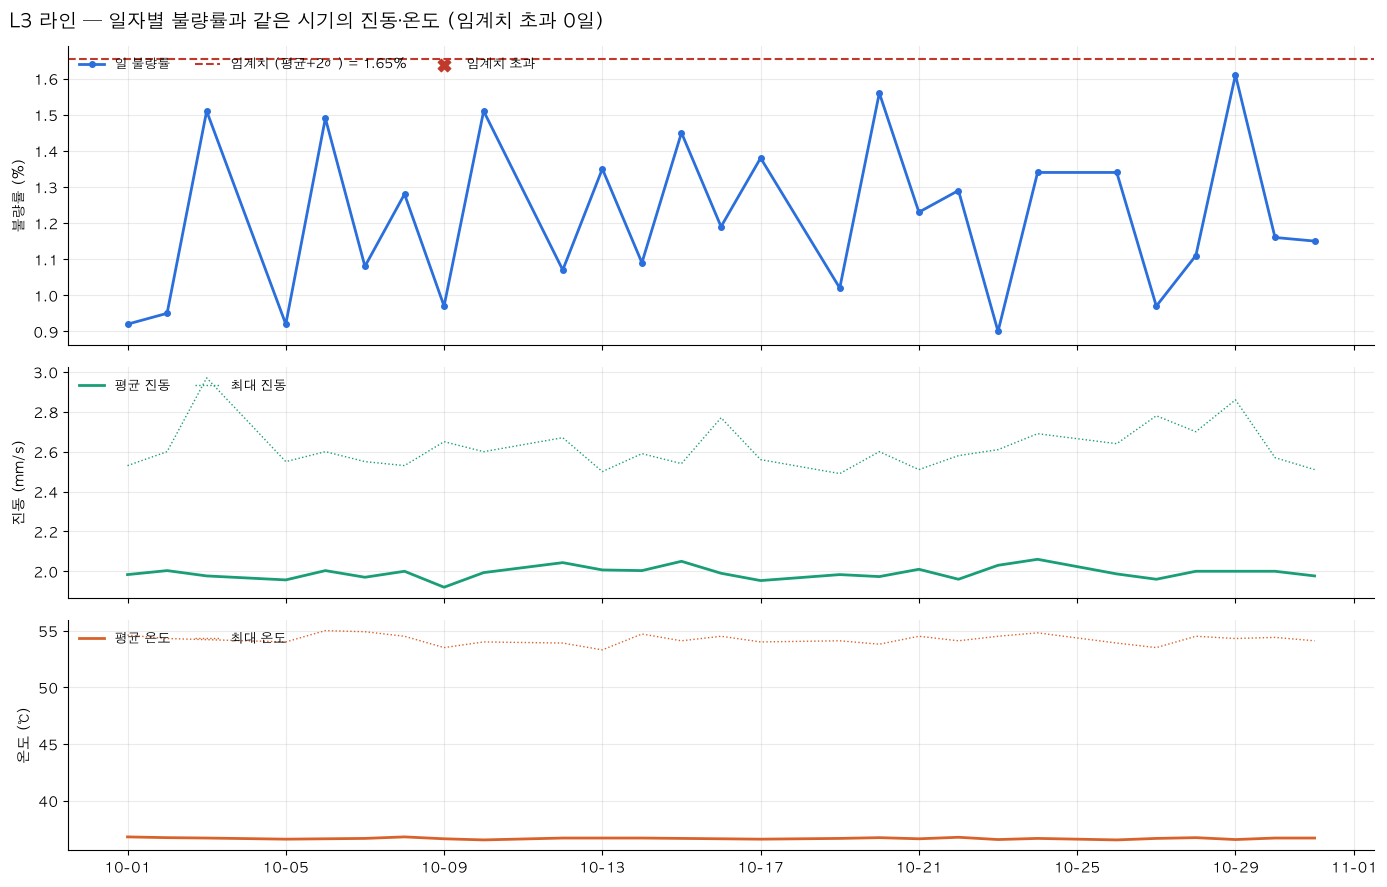

In [91]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
plt.rcParams['font.family'] = 'AppleGothic'
plt.rcParams['axes.unicode_minus'] = False

K = 2

# 라인·일자별로 1행씩 집계
line_daily = q("""
    select work_date, line_code,
           max(defect_rate) as defect_rate,          -- 같은 라인·날짜는 값이 같음
           avg(avg_vib)     as avg_vib,  max(max_vib)  as max_vib,
           avg(avg_temp)    as avg_temp, max(max_temp) as max_temp
    from quality_judgment
    where equip_code is not null
    group by 1, 2
    order by 2, 1
""")
num = ['defect_rate', 'avg_vib', 'max_vib', 'avg_temp', 'max_temp']
line_daily[num] = line_daily[num].astype(float)
line_daily['work_date'] = pd.to_datetime(line_daily['work_date'])

C_RATE, C_VIB, C_TEMP, C_LIMIT = '#2a6fdb', '#1a9e77', '#d9622b', '#c0392b'

def plot_line_trend(line_code):
    d = line_daily[line_daily['line_code'] == line_code]
    limit = d['defect_rate'].mean() + K * d['defect_rate'].std()
    over = d[d['defect_rate'] > limit]

    fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(14, 9), sharex=True,
                                        gridspec_kw={'height_ratios': [1.3, 1, 1]})

    # ① 불량률 + 임계치
    ax1.plot(d['work_date'], d['defect_rate'], color=C_RATE, lw=2, marker='o', ms=4, label='일 불량률')
    ax1.axhline(limit, color=C_LIMIT, ls='--', lw=1.5, label=f'임계치 (평균+{K}σ) = {limit:.2f}%')
    ax1.scatter(over['work_date'], over['defect_rate'], color=C_LIMIT, marker='X', s=80, zorder=3, label='임계치 초과')
    ax1.set_ylabel('불량률 (%)')

    # ② 진동
    ax2.plot(d['work_date'], d['avg_vib'], color=C_VIB, lw=2, label='평균 진동')
    ax2.plot(d['work_date'], d['max_vib'], color=C_VIB, lw=1, ls=':', label='최대 진동')
    ax2.set_ylabel('진동 (mm/s)')

    # ③ 온도
    ax3.plot(d['work_date'], d['avg_temp'], color=C_TEMP, lw=2, label='평균 온도')
    ax3.plot(d['work_date'], d['max_temp'], color=C_TEMP, lw=1, ls=':', label='최대 온도')
    ax3.set_ylabel('온도 (℃)')

    # 임계치 초과일: 세 칸 모두 음영
    for ax in (ax1, ax2, ax3):
        for day in over['work_date']:
            ax.axvspan(day - pd.Timedelta(hours=12), day + pd.Timedelta(hours=12),
                       color=C_LIMIT, alpha=0.08, lw=0)
        ax.legend(loc='upper left', frameon=False, ncol=3, fontsize=9)
        ax.grid(alpha=0.25)
        ax.spines[['top', 'right']].set_visible(False)

    ax3.xaxis.set_major_formatter(mdates.DateFormatter('%m-%d'))
    fig.suptitle(f'{line_code} 라인 — 일자별 불량률과 같은 시기의 진동·온도 '
                 f'(임계치 초과 {len(over)}일)', x=0.01, ha='left', fontsize=14)
    fig.tight_layout()
    plt.show()

for line in line_daily['line_code'].unique():
    plot_line_trend(line)


**7. 보고**: (결론 1문장 + 근거 수치 — 확인하지 못한 원인은 「추가 확인 필요」)

---
## AI 질문 로그

AI에게 한 질문을 그때그때 적습니다. 질문을 하지 않았다면 「질문 없음」이라고 적습니다.

| 시각 | 질문 요지 | 알게 된 것 | 내 코드에 어떻게 적용했는지 |
| --- | --- | --- | --- |
|  |  |  |  |
|  |  |  |  |